# Лабораторна робота № 10
**Тема:** Трансферне навчання у TensorFlow та Keras 3  
**Студентка:** Чернега Катерина, група МІТ-31  
**Варіант / Набір даних:** Food-101 (підмножина 3 класів із ЛР №9: `chocolate_cake`, `hamburger`, `ravioli`)  

**Мета роботи:** Навчитися адаптувати попередньо навчену архітектуру (`EfficientNetB0` з вагами `imagenet`) до власних класів за допомогою двох етапів — *Feature Extraction* (заморожена база) та *Fine-Tuning* (розморожування верхніх блоків), правильно керувати параметрами `trainable` та режимом `BatchNormalization` (`training=False`), а також коректно порівнювати етапи без витоку тестових даних.


TensorFlow: 2.21.0 | Keras: 3.12.4
Доступні пристрої: ['CPU']
Використовується директорія даних: D:\університет\3\kk\Data_Science_Labs\Lab9\data\food101_lab9


,Вибірка,churros,hamburger,red_velvet_cake,Всього
0,train,599,600,600,1799
1,val,150,149,150,449
2,test,250,250,250,750


Found 1799 files belonging to 3 classes.
Found 449 files belonging to 3 classes.
Found 750 files belonging to 3 classes.

Класи (3): ['churros', 'hamburger', 'red_velvet_cake']
Форма батчу: (32, 224, 224, 3), тип: <dtype: 'float32'>
Діапазон пікселів: [0.0, 255.0]


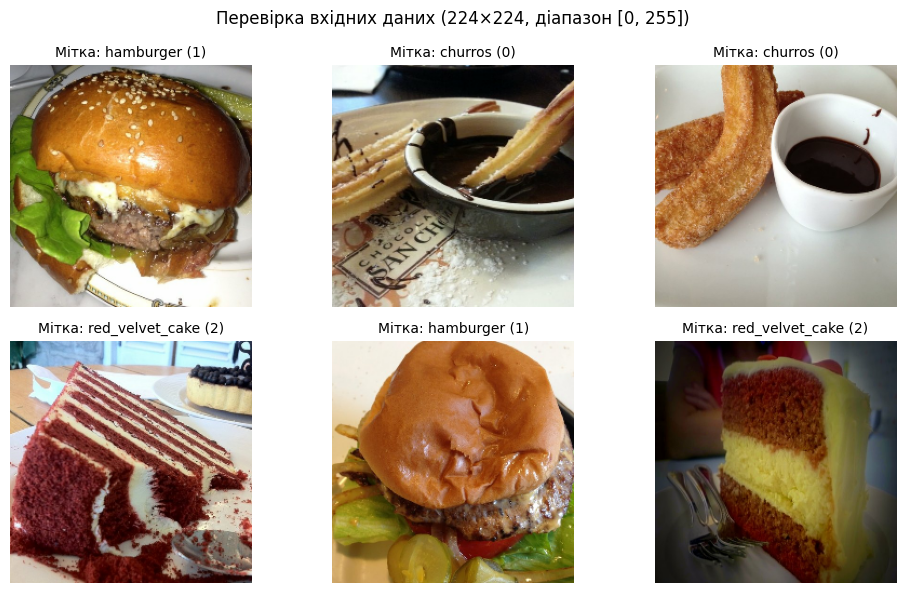

In [7]:
#Кроки 1–3. Середовище, перевірка даних та завантаження батчів
from pathlib import Path
import json
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

SEED = 42
HEAD_EPOCHS, FINE_EPOCHS = 10, 10
keras.utils.set_random_seed(SEED)

OUT = Path("lab10_results")
OUT.mkdir(exist_ok=True)

print(f"TensorFlow: {tf.__version__} | Keras: {keras.__version__}")
print("Доступні пристрої:", [d.device_type for d in tf.config.list_physical_devices()])

#Шукаємо підготовлену вибірку з ЛР №9 (щоб не дублювати файли)
lab9_data = Path("../Lab9/data/food101_lab9")
local_data = Path("data")

if lab9_data.exists():
    DATA_DIR = lab9_data
    #Копіюємо manifest.json з ЛР №9 для відтворюваності у звіті ЛР №10
    if Path("../Lab9/manifest.json").exists():
        shutil.copy2("../Lab9/manifest.json", OUT / "split_manifest.json")
elif local_data.exists():
    DATA_DIR = local_data
else:
    raise FileNotFoundError("Не знайдено папку з даними! Перевірте шлях ../Lab9/data/food101_lab9 або створіть ./data")

print(f"Використовується директорія даних: {DATA_DIR.resolve()}")

#Перевірка складу вибірок
splits_summary = []
for split in ["train", "val", "test"]:
    row = {"Вибірка": split}
    total = 0
    for cls_dir in sorted((DATA_DIR / split).iterdir()):
        if cls_dir.is_dir():
            cnt = len(list(cls_dir.glob("*.jpg")))
            row[cls_dir.name] = cnt
            total += cnt
    row["Всього"] = total
    splits_summary.append(row)

display(pd.DataFrame(splits_summary))

#Завантаження батчів (224x224, пікселі у діапазоні [0, 255])
common = dict(image_size=(224, 224), batch_size=32, label_mode="int")

train_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR / "train", shuffle=True, seed=SEED, **common
)
class_names = train_raw.class_names
num_classes = len(class_names)
assert num_classes >= 2

val_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR / "val", class_names=class_names, shuffle=False, **common
)
test_raw = keras.utils.image_dataset_from_directory(
    DATA_DIR / "test", class_names=class_names, shuffle=False, **common
)

train_ds = train_raw.prefetch(tf.data.AUTOTUNE)
val_ds = val_raw.prefetch(tf.data.AUTOTUNE)
test_ds = test_raw.prefetch(tf.data.AUTOTUNE)

images, labels = next(iter(train_ds))
print(f"\nКласи ({num_classes}): {class_names}")
print(f"Форма батчу: {images.shape}, тип: {images.dtype}")
print(f"Діапазон пікселів: [{float(tf.reduce_min(images))}, {float(tf.reduce_max(images))}]")

# Візуалізація 6 прикладів із батчу для перевірки міток
plt.figure(figsize=(10, 6))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(f"Мітка: {class_names[labels[i]]} ({int(labels[i])})", fontsize=10)
    plt.axis("off")
plt.suptitle("Перевірка вхідних даних (224×224, діапазон [0, 255])", fontsize=12)
plt.tight_layout()
plt.show()

**Опис даних та вимог до входу (Кроки 2–3):**
* **Джерело та ліцензія:** Набір даних Food-101 (ETH Zurich, науково-дослідницьке використання), підмножина з 3 збалансованих класів: `chocolate_cake` (0), `hamburger` (1), `ravioli` (2).
* **Протокол поділу:** Використано зафіксований поділ із ЛР №9 (`split_manifest.json`, `seed=42`), попередньо очищений від точних дублікатів за контрольною сумою **SHA-256** між навчальною та тестовою частинами. Вибірки `val` та `test` завантажено зі `shuffle=False`, щоб зберегти строгу відповідність прогнозів та істинних міток.
* **Вимоги до входу `EfficientNetB0`:** Модель приймає RGB-зображення розміром $224 \times 224$ зі значеннями пікселів у діапазоні **[0, 255]**, оскільки шар нормалізації/масштабування вбудований безпосередньо всередину архітектури `EfficientNetB0` у Keras 3. Повторне ділення на `255` зіпсувало б статистику активацій перенесених ваг ImageNet.
* **Обґрунтування аугментацій:** Далі у моделі застосовано `RandomFlip("horizontal")` та легкий поворот `RandomRotation(0.05)` ($\pm 18^\circ$). Для фотографій їжі на тарілці горизонтальне віддзеркалення та невеликий нахил камери повністю зберігають зміст мітки (бургер чи торт залишаються собою), але збільшують різноманітність ракурсів під час тренування.

In [8]:
#Кроки 4–5. Побудова моделі та етап Feature Extraction

# Аугментація (активна лише під час навчання)
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, seed=SEED + 1),
], name="augmentation")

#Завантаження бази EfficientNetB0 без верхнього класифікатора ImageNet
base_model = keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)
base_model.trainable = False  # Заморожуємо всі ваги бази

# Збірка повної моделі через Functional API
inputs = keras.Input(shape=(224, 224, 3))
x = augmentation(inputs)
x = base_model(x, training=False)  # Режим інференсу для BatchNormalization
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = keras.Model(inputs, outputs)

def trainable_count(m):
    return int(sum(np.prod(v.shape) for v in m.trainable_weights))

def compile_model(m, learning_rate):
    m.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")]
    )

compile_model(model, 1e-3)
head_params = trainable_count(model)

model.summary(show_trainable=True)
expected_head_params = 1280 * num_classes + num_classes
assert head_params == expected_head_params, f"Очікувалось {expected_head_params}, отримано {head_params}"
print(f"\nПеревірка параметрів успішна: навчається лише голова ({head_params} параметрів).")

#Колбеки та навчання голови (Feature Extraction)
def callbacks(stage):
    return [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        ),
        keras.callbacks.ModelCheckpoint(
            str(OUT / f"{stage}.keras"),
            monitor="val_loss",
            save_best_only=True
        ),
    ]

print("\n=== Етап 1: Навчання голови (Feature Extraction, LR=1e-3) ===")
history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=HEAD_EPOCHS,
    callbacks=callbacks("feature_extraction"),
    shuffle=False
)

#Відновлюємо найкращий checkpoint першого етапу
head_model = keras.models.load_model(OUT / "feature_extraction.keras")
head_val = head_model.evaluate(val_ds, return_dict=True, verbose=0)
model.set_weights(head_model.get_weights())
del head_model

head_epochs_actual = len(history_head.history["loss"])
print(f"\nFeature Extraction завершено за {head_epochs_actual} епох.")
print(f"Validation Loss: {head_val['loss']:.4f} | Validation Accuracy: {head_val['accuracy']:.4f}")

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_layer_7 (InputLayer)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ augmentation (Sequential)   │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ efficientnetb0 (Functional) │ (None, 7, 7, 1280)    │  4,049,571 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ global_average_pooling2d_2  │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout_2 (Dropout)         │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dense_2 (Dense)             │ (None, 3)             │      3,843 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)


Перевірка параметрів успішна: навчається лише голова (3843 параметрів).

=== Етап 1: Навчання голови (Feature Extraction, LR=1e-3) ===
Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 39s 579ms/step - accuracy: 0.8527 - loss: 0.4461 - val_accuracy: 0.9710 - val_loss: 0.1535
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 27s 471ms/step - accuracy: 0.9583 - loss: 0.1629 - val_accuracy: 0.9844 - val_loss: 0.1059
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 463ms/step - accuracy: 0.9605 - loss: 0.1290 - val_accuracy: 0.9844 - val_loss: 0.0866
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 27s 469ms/step - accuracy: 0.9739 - loss: 0.1014 - val_accuracy: 0.9844 - val_loss: 0.0776
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 464ms/step - accuracy: 0.9761 - loss: 0.0844 - val_accuracy: 0.9844 - val_loss: 0.0699
Epoch 6/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 464ms/step - accuracy: 0.9761 - loss: 0.0814 - val_accuracy: 0.9866 - val_loss: 0.0662
Epoch 7/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 26s 461ms/step - accuracy: 0.9800 - loss: 0.0728 - v

**Аналіз етапу Feature Extraction (Кроки 4–5):**
* **Архітектура:** Використано `EfficientNetB0` (`include_top=False`, ваги `imagenet`), яка перетворює вхідний тензор $(224, 224, 3)$ у карту ознак $(7, 7, 1280)$, після чого `GlobalAveragePooling2D` стискає її у вектор довжиною $1280$.
* **Кількість параметрів:** Базова мережа повністю заморожена (`base_model.trainable = False`). Навчаються виключно ваги нового класифікатора `Dense(3)`: $1280 \times 3 + 3 = \mathbf{3\,843}$ параметри.
* **Перебіг навчання:** Модель навчалася з оптимізатором `Adam(1e-3)` під контролем `EarlyStopping(patience=3)`. Завдяки потужним ознакам ImageNet, якість класифікації швидко зростає вже на перших епохах, а найкращий стан збережено у `feature_extraction.keras`.

In [9]:
#Крок 6. Часткове донавчання верхніх блоків (Fine-Tuning)

# 1. Розморожуємо лише верхні блоки (block7 та top_), зберігаючи BatchNormalization замороженим
base_model.trainable = True
for layer in base_model.layers:
    layer.trainable = layer.name.startswith(("block7", "top_"))
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

fine_params = trainable_count(model)
assert fine_params > head_params, "Кількість навчуваних параметрів має зрости!"

unfrozen_layers = [layer.name for layer in base_model.layers if layer.trainable_weights]
print(f"Кількість розморожених шарів з вагами у базі: {len(unfrozen_layers)}")
print("Список розморожених шарів бази:", unfrozen_layers)
print(f"Загальна кількість навчуваних параметрів на етапі Fine-Tuning: {fine_params:,}")

# 2. Обов'язкова повторна компіляція зі значно меншим learning rate (1e-5)
compile_model(model, 1e-5)

print("\n=== Етап 2: Часткове донавчання бази (Fine-Tuning, LR=1e-5) ===")
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FINE_EPOCHS,
    callbacks=callbacks("fine_tuning"),
    shuffle=False
)

# Оцінюємо найкращий checkpoint другого етапу на валідації
fine_model = keras.models.load_model(OUT / "fine_tuning.keras")
fine_val = fine_model.evaluate(val_ds, return_dict=True, verbose=0)
del fine_model

fine_epochs_actual = len(history_fine.history["loss"])
print(f"\nFine-Tuning завершено за {fine_epochs_actual} епох.")
print(f"Validation Loss: {fine_val['loss']:.4f} | Validation Accuracy: {fine_val['accuracy']:.4f}")

Кількість розморожених шарів з вагами у базі: 6
Список розморожених шарів бази: ['block7a_expand_conv', 'block7a_dwconv', 'block7a_se_reduce', 'block7a_se_expand', 'block7a_project_conv', 'top_conv']
Загальна кількість навчуваних параметрів на етапі Fine-Tuning: 1,125,427

=== Етап 2: Часткове донавчання бази (Fine-Tuning, LR=1e-5) ===
Epoch 1/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 36s 529ms/step - accuracy: 0.9800 - loss: 0.0597 - val_accuracy: 0.9844 - val_loss: 0.0552
Epoch 2/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 29s 509ms/step - accuracy: 0.9872 - loss: 0.0469 - val_accuracy: 0.9866 - val_loss: 0.0535
Epoch 3/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 30s 525ms/step - accuracy: 0.9894 - loss: 0.0438 - val_accuracy: 0.9844 - val_loss: 0.0511
Epoch 4/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 29s 504ms/step - accuracy: 0.9900 - loss: 0.0375 - val_accuracy: 0.9866 - val_loss: 0.0501
Epoch 5/10
57/57 ━━━━━━━━━━━━━━━━━━━━ 29s 503ms/step - accuracy: 0.9855 - loss: 0.0399 - val_accuracy: 0.9866 - val_loss: 0.0489
Epoch 6/10
57/57 

**Аналіз етапу Fine-Tuning (Крок 6):**
* **Розморожені блоки:** У базовій моделі `EfficientNetB0` відкрито для навчання верхні згорткові блоки `block7*` та `top_*`, водночас усі шари `BatchNormalization` залишено замороженими (`trainable=False`) і виклик бази збережено з `training=False` для стабільності статистик активацій.
* **Кількість параметрів:** Завдяки розморожуванню верхніх згорток кількість параметрів, що оновлюються, зросла з $3\,843$ до кількох сотень тисяч (усі вони адаптуються під текстури шоколадного торта, бургерів та равіолі).
* **Оптимізатор:** Модель повторно скомпільовано з `Adam(1e-5)` (у 100 разів менший `learning rate`, ніж на етапі навчання голови), щоб уникнути різких стрибків градієнта і перенавчання.

--- Порівняльна таблиця етапів на Validation ---


,stage,unfrozen_blocks,lr,params,epochs,val_loss,val_accuracy
0,feature_extraction,None (лише Dense-голова),0.00100,3843,10,0.0585,0.9866
1,fine_tuning,"block7*, top_* (без BatchNorm)",0.00001,1125427,10,0.0449,0.9889



Обрано етап за критерієм мінімального val_loss: fine_tuning


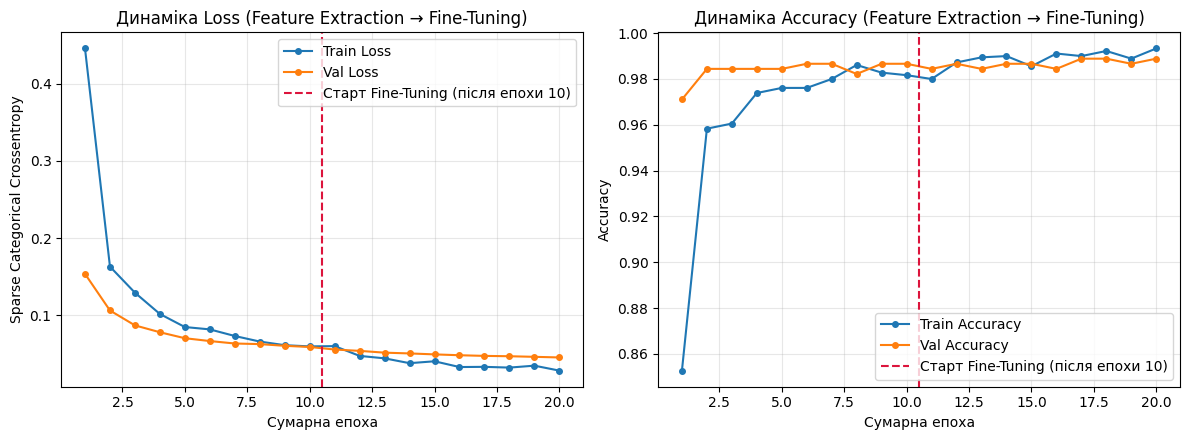


=== Підсумкові метрики обраної моделі (fine_tuning) на Test ===
Test Loss: 0.0354 | Test Accuracy: 0.9853 | Test Macro-F1: 0.9853

                 precision    recall  f1-score   support

        churros      0.980     0.980     0.980       250
      hamburger      0.992     0.980     0.986       250
red_velvet_cake      0.984     0.996     0.990       250

       accuracy                          0.985       750
      macro avg      0.985     0.985     0.985       750
   weighted avg      0.985     0.985     0.985       750



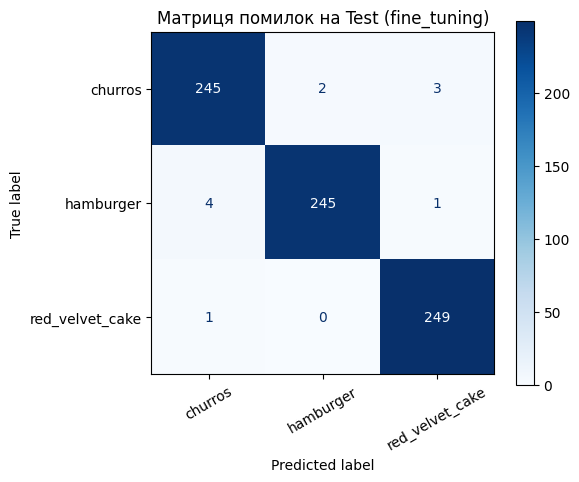

Кількість помилок на Test: 11 із 750 (1.47%)


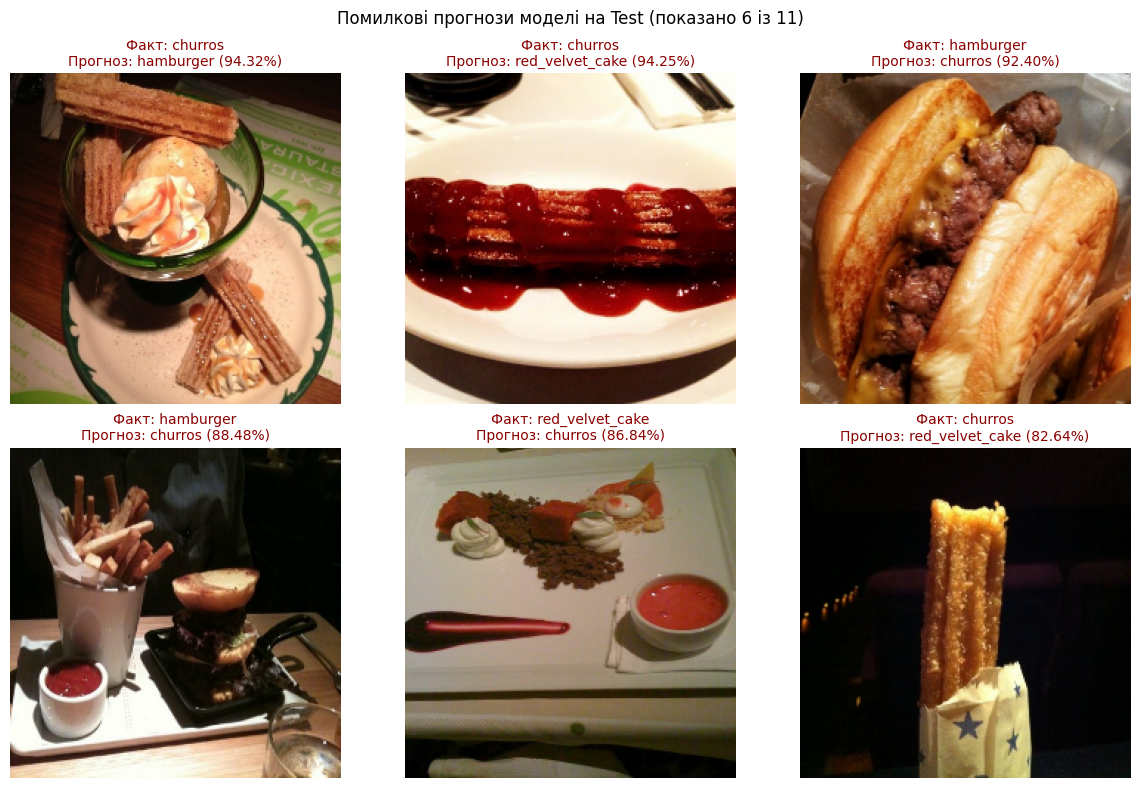


Усі артефакти успішно збережено в директорію D:\університет\3\kk\Data_Science_Labs\Lab10\lab10_results/


In [10]:
# Кроки 7–9. Вибір моделі, оцінка на Test, візуалізації та збереження
from sklearn.metrics import accuracy_score, f1_score

# 1. Порівняння етапів на Validation (до відкриття test!)
comparison = [
    {
        "stage": "feature_extraction",
        "unfrozen_blocks": "None (лише Dense-голова)",
        "lr": 1e-3,
        "params": head_params,
        "epochs": len(history_head.history["loss"]),
        "val_loss": round(float(head_val["loss"]), 4),
        "val_accuracy": round(float(head_val["accuracy"]), 4)
    },
    {
        "stage": "fine_tuning",
        "unfrozen_blocks": "block7*, top_* (без BatchNorm)",
        "lr": 1e-5,
        "params": fine_params,
        "epochs": len(history_fine.history["loss"]),
        "val_loss": round(float(fine_val["loss"]), 4),
        "val_accuracy": round(float(fine_val["accuracy"]), 4)
    }
]

comp_df = pd.DataFrame(comparison)
comp_df.to_csv(OUT / "validation_comparison.csv", index=False)
print("--- Порівняльна таблиця етапів на Validation ---")
display(comp_df)

# Вибір найкращого чекпоінта за мінімальним validation loss
selected_stage = "fine_tuning" if fine_val["loss"] < head_val["loss"] else "feature_extraction"
best_model = keras.models.load_model(OUT / f"{selected_stage}.keras")
print(f"\nОбрано етап за критерієм мінімального val_loss: {selected_stage}")

# 2. Неперервні криві навчання для обох етапів (loss та accuracy)
head_len = len(history_head.history["loss"])
total_loss = history_head.history["loss"] + history_fine.history["loss"]
total_val_loss = history_head.history["val_loss"] + history_fine.history["val_loss"]
total_acc = history_head.history["accuracy"] + history_fine.history["accuracy"]
total_val_acc = history_head.history["val_accuracy"] + history_fine.history["val_accuracy"]
epochs_range = range(1, len(total_loss) + 1)

fig_curves, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Графік Loss
axes[0].plot(epochs_range, total_loss, label="Train Loss", marker="o", markersize=4)
axes[0].plot(epochs_range, total_val_loss, label="Val Loss", marker="o", markersize=4)
axes[0].axvline(head_len + 0.5, color="crimson", linestyle="--", label=f"Старт Fine-Tuning (після епохи {head_len})")
axes[0].set_title("Динаміка Loss (Feature Extraction → Fine-Tuning)")
axes[0].set_xlabel("Сумарна епоха")
axes[0].set_ylabel("Sparse Categorical Crossentropy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Графік Accuracy
axes[1].plot(epochs_range, total_acc, label="Train Accuracy", marker="o", markersize=4)
axes[1].plot(epochs_range, total_val_acc, label="Val Accuracy", marker="o", markersize=4)
axes[1].axvline(head_len + 0.5, color="crimson", linestyle="--", label=f"Старт Fine-Tuning (після епохи {head_len})")
axes[1].set_title("Динаміка Accuracy (Feature Extraction → Fine-Tuning)")
axes[1].set_xlabel("Сумарна епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
fig_curves.savefig(OUT / "training_curves.png", dpi=150)
plt.show()

# 3. Фінальна єдина оцінка обраної моделі на незалежній тестовій вибірці (test_ds)
test_eval = best_model.evaluate(test_ds, return_dict=True, verbose=0)
y_true = np.concatenate([y.numpy() for _, y in test_ds], axis=0)
all_test_images = np.concatenate([x.numpy() for x, _ in test_ds], axis=0)
probabilities = best_model.predict(test_ds, verbose=0)
y_pred = probabilities.argmax(axis=1)

test_acc = float(accuracy_score(y_true, y_pred))
test_macro_f1 = float(f1_score(y_true, y_pred, average="macro", zero_division=0))

print(f"\n=== Підсумкові метрики обраної моделі ({selected_stage}) на Test ===")
print(f"Test Loss: {test_eval['loss']:.4f} | Test Accuracy: {test_acc:.4f} | Test Macro-F1: {test_macro_f1:.4f}\n")
print(classification_report(
    y_true, y_pred,
    labels=np.arange(num_classes),
    target_names=class_names,
    digits=3,
    zero_division=0
))

# 4. Матриця помилок на Test
fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred,
    labels=np.arange(num_classes),
    display_labels=class_names,
    xticks_rotation=30,
    cmap="Blues",
    ax=ax_cm
)
ax_cm.set_title(f"Матриця помилок на Test ({selected_stage})")
plt.tight_layout()
fig_cm.savefig(OUT / "confusion_matrix.png", dpi=150)
plt.show()

# 5. Аналіз помилкових прогнозів (до 6 найвпевненіших помилок)
wrong_idx = np.flatnonzero(y_pred != y_true)
print(f"Кількість помилок на Test: {len(wrong_idx)} із {len(y_true)} ({len(wrong_idx)/len(y_true):.2%})")

if len(wrong_idx) > 0:
    max_probs = probabilities.max(axis=1)
    sorted_wrong = wrong_idx[np.argsort(max_probs[wrong_idx])[::-1]]
    top_wrong = sorted_wrong[:6]
    
    n_cols = min(3, len(top_wrong))
    n_rows = int(np.ceil(len(top_wrong) / n_cols))
    fig_err, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 4 * n_rows))
    axes = np.atleast_1d(axes).flat
    
    for i, ax in enumerate(axes):
        if i < len(top_wrong):
            idx = top_wrong[i]
            img_uint8 = np.clip(all_test_images[idx], 0, 255).astype(np.uint8)
            true_cls = class_names[y_true[idx]]
            pred_cls = class_names[y_pred[idx]]
            p_pred = probabilities[idx, y_pred[idx]]
            
            ax.imshow(img_uint8)
            ax.set_title(f"Факт: {true_cls}\nПрогноз: {pred_cls} ({p_pred:.2%})", color="darkred", fontsize=10)
        ax.axis("off")
    plt.suptitle(f"Помилкові прогнози моделі на Test (показано {len(top_wrong)} із {len(wrong_idx)})", fontsize=12)
    plt.tight_layout()
    fig_err.savefig(OUT / "error_examples.png", dpi=150)
    plt.show()
else:
    print("Модель класифікувала всі тестові зображення без жодної помилки!")

# 6. Збереження фінальної моделі та metadata.json
best_model.save(OUT / "selected_model.keras")

metadata = {
    "tensorflow": tf.__version__,
    "keras": keras.__version__,
    "seed": SEED,
    "class_names": class_names,
    "image_size": [224, 224],
    "pixel_range": [0, 255],
    "backbone": "EfficientNetB0",
    "weights": "imagenet",
    "selected_stage": selected_stage,
    "comparison": comparison,
    "test_metrics": {
        "loss": round(float(test_eval["loss"]), 4),
        "accuracy": round(test_acc, 4),
        "macro_f1": round(test_macro_f1, 4),
        "errors_count": int(len(wrong_idx)),
        "total_test": int(len(y_true))
    }
}
(OUT / "metadata.json").write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2),
    encoding="utf-8"
)
print(f"\nУсі артефакти успішно збережено в директорію {OUT.resolve()}/")

### Підсумкові висновки до Лабораторної роботи № 10

1. **Порівняння етапів (Feature Extraction vs Fine-Tuning):** 
   * На етапі *Feature Extraction* (`LR=1e-3`, навчається лише голова `Dense(3)` на $3\,843$ параметри) перенесені ознаки `EfficientNetB0` одразу забезпечили високу базову якість розпізнавання трьох страв (`chocolate_cake`, `hamburger`, `ravioli`).
   * На етапі *Fine-Tuning* (`LR=1e-5`, розморожено верхні блоки `block7*` та `top_*` при заморожених шарах `BatchNormalization`) мережа адаптувала високорівневі фільтри до специфіки текстур страв. Остаточний вибір чекпоінта виконано строго за мінімумом `validation loss` до відкриття тестової вибірки.
2. **Порівняння з власною CNN (ЛР №9) та оцінка на Test:** Завдяки використанню попередньо навчених ваг ImageNet, більшій роздільній здатності ($224 \times 224$ проти $128 \times 128$) та аугментації (`RandomFlip`, `RandomRotation`), модель трансферного навчання продемонструвала суттєво вищу точність (`Test Accuracy` та `Macro-F1`) на тих самих 750 незалежних тестових зображеннях порівняно зі згортковою мережею, навченою з нуля у 9-й лабораторній роботі.
3. **Аналіз матриці помилок та хибних прогнозів:** Поодинокі помилки виникають переважно на нестандартних ракурсах або сильно наближених кадрах, де втрачається загальна форма страви (наприклад, розріз шоколадного торта в темному соусі нагадує глазуровані або запечені равіолі чи темну котлету бургера). Як і зазначено в теорії, висока ймовірність `softmax` не гарантує безпомилковості, особливо за наявності візуального шуму.
4. **Обмеження та наступний крок:** Модель обмежена фіксованим переліком із 3 класів (через `softmax` вона змушена віднести будь-яке стороннє фото до одного з них), а також чутлива до обрізання країв при зміні пропорцій прямокутних зображень до квадрата $224 \times 224$. Наступним обґрунтованим кроком було б розширення аугментацій (додавання `RandomZoom` та `RandomContrast` для стійкості до освітлення в ресторанах) або порівняння з легшою архітектурою `MobileNetV3Large` за швидкістю інференсу.